# Учебный расчёт по «Ивангородскому городскому поселению» в BlocksNet

Ноутбук использует **готовые векторные слои** из `data/input/Ивангородское городское поселение/`:
`blocks.geojson`, `building.geojson`, `landuse.geojson`, `roads.geojson`, `railways.geojson`,
`river.geojson`, `water.geojson` и папку `сервисы/`.

Основной пешеходный граф строится по `roads.geojson`. Дополнительную проверку по OSM можно
включить флагом `BUILD_OSM = True` — она требует интернет и не влияет на основные результаты.

Расчёт выполняет `pipeline.py`, результаты сохраняются в `data/processed/` и `results/`,
итоговый дашборд собирает `report.py`.

## 0. Настройка окружения

- `BUILD_OSM = False` — основной граф из `roads.geojson`; при `True` дополнительно строится OSM-граф.
- `RUN_PIPELINE = True` — пересчитать все слои. При `False` ноутбук читает уже сохранённые файлы.

In [1]:
from __future__ import annotations

import os
import pickle
import subprocess
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import IFrame, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "pipeline.py").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
INPUT_ROOT = ROOT / "data" / "input"

BUILD_OSM = False
RUN_PIPELINE = True

plt.rcParams["figure.figsize"] = (10, 8)
plt.rcParams["axes.titlesize"] = 12
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

print(f"Корень проекта: {ROOT}")


def show_layer(gdf, title, column=None, cmap="viridis", legend=True, figsize=(10, 8)):
    if gdf is None or len(gdf) == 0:
        print(f"{title}: слой пустой")
        return
    fig, ax = plt.subplots(figsize=figsize)
    if column is None:
        gdf.plot(ax=ax, color="#d9e8d0", edgecolor="#555555", linewidth=0.5)
    else:
        gdf.plot(ax=ax, column=column, cmap=cmap, legend=legend, edgecolor="#555555", linewidth=0.3)
    ax.set_title(title)
    ax.set_axis_off()
    plt.show()

Корень проекта: D:\магистратура\3_ТИИ\ivangorod-blocksnet


## 1. Запуск расчёта

`pipeline.run_pipeline()` последовательно выполняет:
загрузку слоёв → подготовку кварталов → землепользование → агрегацию зданий →
сервисы → граф → матрицу доступности → плотность и морфотипы → обеспеченность →
итоговый слой и проверки.

In [2]:
import pipeline

if RUN_PIPELINE:
    results = pipeline.run_pipeline(build_osm=BUILD_OSM)
else:
    results = {}
    print("Расчёт пропущен, используются сохранённые файлы.")

Территория: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\input\Ивангородское городское поселение
Сервисы: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\input\Ивангородское городское поселение\сервисы
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\boundary.geojson
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\input_blocks.geojson
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\buildings.geojson


2026-10-23 18:01:19.507 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\landuse.geojson
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\roads.geojson
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\railways.geojson
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\river.geojson
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\water.geojson
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\blocks.geojson
Кварталов: 129
Площадь кварталов: 53.58 км²
Зоны без правила: нет
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\blocks_land_use.geojson
Распределение land use:
land_use
residential    50
recreation     45
agriculture    13
special         8
industrial      6
business        4
transport       3
Пропусков в полях зданий нет — готовые атрибуты используются как есть.


2026-10-23 18:01:19.509 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\data\processed\buildings_blocks.geojson
Зданий: 1082
Суммарное население: 9,635 чел.
Площадь застройки: 392,294 м²


...

2026-10-23 18:01:22.709 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


Доступность сервисов по группам:
   service_group  objects_total  median_nearest_min  share_blocks_within_15
       транспорт             30            7.541636                0.651163
        торговля             34            9.179631                0.581395
          услуги             14           10.644430                0.565891
          туризм              6           13.293418                0.558140
         общепит              7           15.905165                0.488372
  инфраструктура             50            5.519975                0.713178
         природа             31            9.189341                0.759690
     специальное             20           10.049022                0.581395
          прочее              4           16.102248                0.449612
  промышленность              4           18.621019                0.356589
       рекреация             30            6.600998                0.720930
        культура             21            9.780937    

2026-10-23 18:01:22.710 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


2026-10-23 18:01:22.737 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


kindergarten: доступность 7 мин, норматив 61 на 1000 жителей, сильная обеспеченность 0.228
Сохранено: D:\магистратура\3_ТИИ\ivangorod-blocksnet\results\blocks_metrics.geojson
Строк в итоговом слое: 129
Колонки итогового слоя:
geometry, land_use, share, source_fid, residential, business, recreation, industrial, transport, special, agriculture, is_living, number_of_floors, footprint_area, build_floor_area, living_area, non_living_area, population, buildings_count, capacity, schools_count, capacity_is_estimate, kindergarten_capacity, kindergartens_count, kindergarten_capacity_is_estimate, site_area, fsi, gsi, mxi, l, osr, share_living, share_non_living, spacematrix_cluster, spacematrix_morphotype, strelka_morphotype, demand, demand_left, demand_within, demand_without, capacity_left, capacity_within, capacity_without, provision_strong, provision_weak, kindergarten_demand, kindergarten_demand_left, kindergarten_demand_within, kindergarten_demand_without, kindergarten_capacity_left, kinderga

## 2. Исходные данные и кварталы

Кварталы берутся как есть из `blocks.geojson`; добавляется уникальный `block_id`,
исходный `FID` сохраняется в `source_fid`. Площадь и население считаются по готовым атрибутам.

,Слой,Объектов,Характеристика
0,Территория,Ивангородское городское поселение,68.80 км²
1,Кварталы,129,53.58 км²
2,Здания,1082,0.40 млн м² застройки
3,Землепользование,471,20 функций
4,Дороги,414,124.7 км
5,Сервисы,280,71 типов


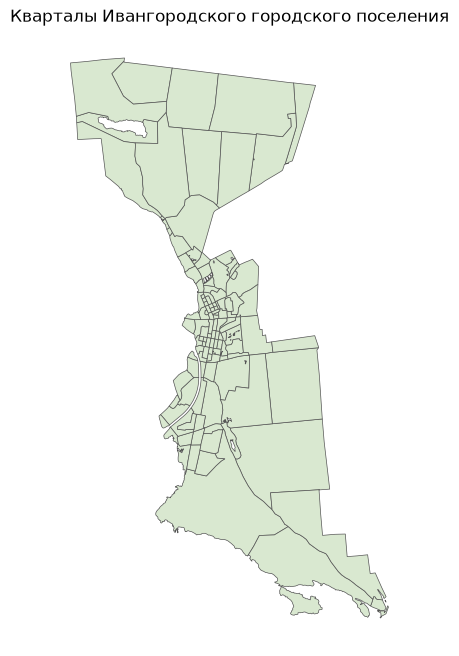

In [3]:
boundary = gpd.read_file(PROCESSED_DIR / "boundary.geojson")
blocks = gpd.read_file(PROCESSED_DIR / "blocks.geojson")
buildings = gpd.read_file(PROCESSED_DIR / "buildings.geojson")
landuse = gpd.read_file(PROCESSED_DIR / "landuse.geojson")
roads = gpd.read_file(PROCESSED_DIR / "roads.geojson")
services = gpd.read_file(PROCESSED_DIR / "services_all.geojson")

boundary_area = boundary.to_crs(32635).area.sum() / 1e6
blocks_area = blocks.to_crs(32635).area.sum() / 1e6
roads_length = roads.to_crs(32635).length.sum() / 1000
summary_rows = [
    ("Территория", boundary["name"].iloc[0] if "name" in boundary.columns else "—", f"{boundary_area:.2f} км²"),
    ("Кварталы", len(blocks), f"{blocks_area:.2f} км²"),
    ("Здания", len(buildings), f"{buildings['footprint_area'].sum() / 1e6:.2f} млн м² застройки"),
    ("Землепользование", len(landuse), f"{landuse['function'].nunique() if 'function' in landuse.columns else '—'} функций"),
    ("Дороги", len(roads), f"{roads_length:.1f} км"),
    ("Сервисы", len(services), f"{services['service_type'].nunique()} типов"),
]
display(pd.DataFrame(summary_rows, columns=["Слой", "Объектов", "Характеристика"]))
show_layer(blocks, "Кварталы Ивангородского городского поселения")

## 3. Землепользование

Функциональные зоны из `landuse.geojson` переводятся в категории BlocksNet
(`residential`, `business`, `recreation`, `industrial`, `transport`, `special`, `agriculture`).
Доля считается по площади наложения, а не по центроидам кварталов.

,quartals,area_km2,population
land_use,,,
recreation,45,45.342044,1222.0
agriculture,13,3.090304,0.0
residential,50,2.613215,8176.0
industrial,6,1.124294,0.0
transport,3,0.729082,0.0
special,8,0.508643,2.0
business,4,0.172023,235.0


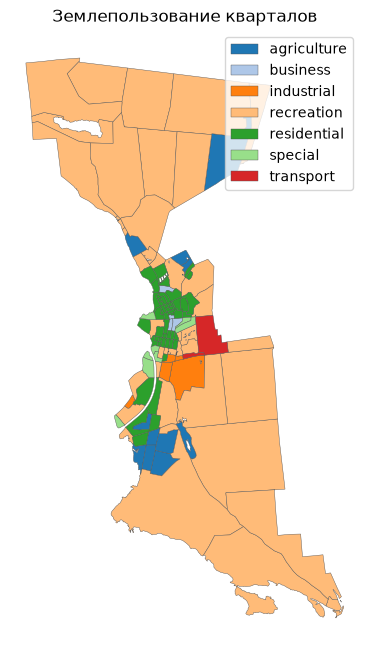

In [4]:
blocks_land_use = gpd.read_file(PROCESSED_DIR / "blocks_land_use.geojson").to_crs(32635)
metrics_for_land = gpd.read_file(RESULTS_DIR / "blocks_metrics.geojson")
population_by_block = metrics_for_land.set_index("block_id")["population"]
blocks_land_use["population"] = blocks_land_use["block_id"].map(population_by_block)
blocks_land_use["area_km2"] = blocks_land_use.area / 1e6
land_summary = (
    blocks_land_use.groupby("land_use", dropna=False)
    .agg(quartals=("block_id", "count"), area_km2=("area_km2", "sum"), population=("population", "sum"))
    .sort_values("area_km2", ascending=False)
)
display(land_summary)
show_layer(blocks_land_use.to_crs(4326), "Землепользование кварталов", column="land_use", cmap="tab20")

## 4. Здания и плотность застройки

Поля `population`, `living_area`, `build_floor_area`, `number_of_floors` уже заполнены
в `building.geojson`, поэтому импутация не требуется. Здания агрегируются в кварталы,
затем рассчитываются FSI, GSI, MXI, L, OSR.

,count,mean,std,min,25%,50%,75%,max
population,129.0,74.689922,229.613459,0.0,0.0,0.000,35.000,1626.000
footprint_area,129.0,3041.041977,6952.297764,0.0,0.0,563.464,2865.308,50041.741
build_floor_area,129.0,5323.108411,13139.523795,0.0,0.0,563.464,3944.023,91880.122
living_area,129.0,2498.759605,7837.872069,0.0,0.0,0.000,1013.494,55379.904


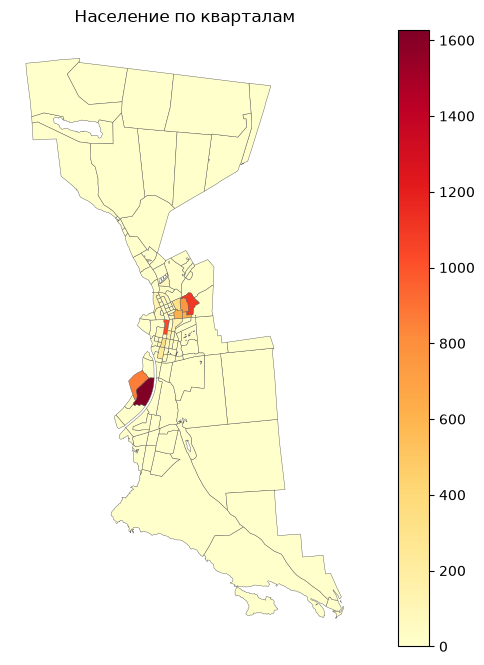

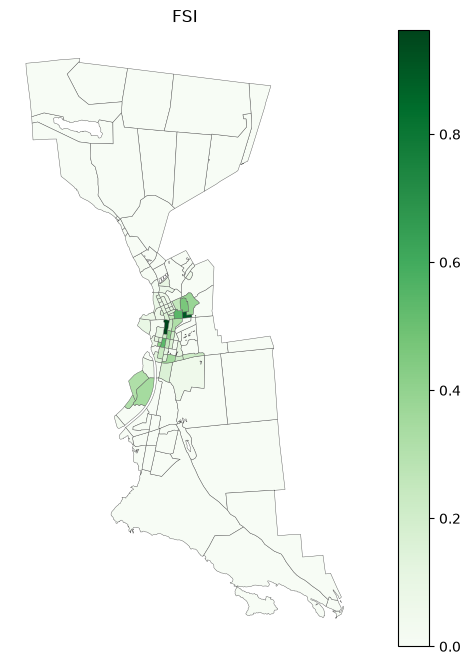

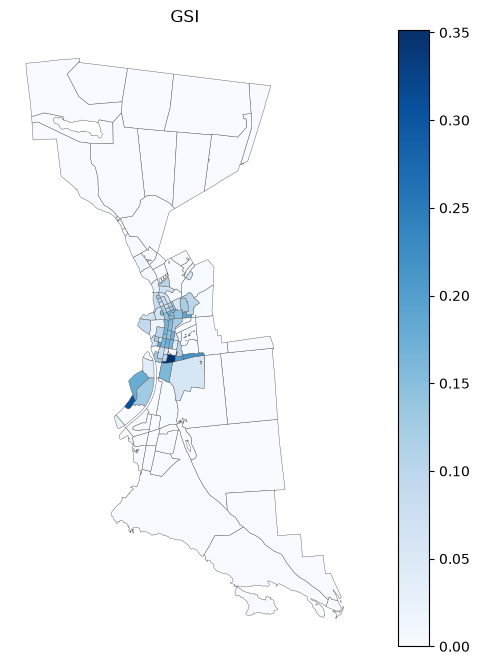

In [5]:
buildings_blocks = gpd.read_file(PROCESSED_DIR / "buildings_blocks.geojson")
metrics = gpd.read_file(RESULTS_DIR / "blocks_metrics.geojson")
density_columns = ["population", "buildings_count", "footprint_area", "build_floor_area", "living_area", "fsi", "gsi", "mxi", "l", "osr"]
display(buildings_blocks[[c for c in density_columns if c in buildings_blocks.columns]].describe().T)
show_layer(metrics, "Население по кварталам", column="population", cmap="YlOrRd")
show_layer(metrics, "FSI", column="fsi", cmap="Greens")
show_layer(metrics, "GSI", column="gsi", cmap="Blues")

## 5. Сервисы, школы и детские сады

По школам и детским садам используется готовая вместимость `capacity`.
Для остальных сервисов считаются количество, плотность и разнообразие по типам.

,Школы,Детские сады
Объектов,2.0,3.0
"Суммарная вместимость, мест",1080.0,542.0


,service_type,service_group,service_sphere,objects,capacity_sum
0,bar,общепит,consumer,1,0.0
1,cafe,общепит,consumer,5,0.0
2,restaurant,общепит,consumer,1,0.0
3,bakery,торговля,consumer,1,0.0
4,clothes,торговля,consumer,6,0.0
...,...,...,...,...,...
66,playground,рекреация,social,3,0.0
67,sport_centre,рекреация,social,1,0.0
68,stadium,рекреация,social,7,0.0
69,swimming_pool,рекреация,social,1,0.0


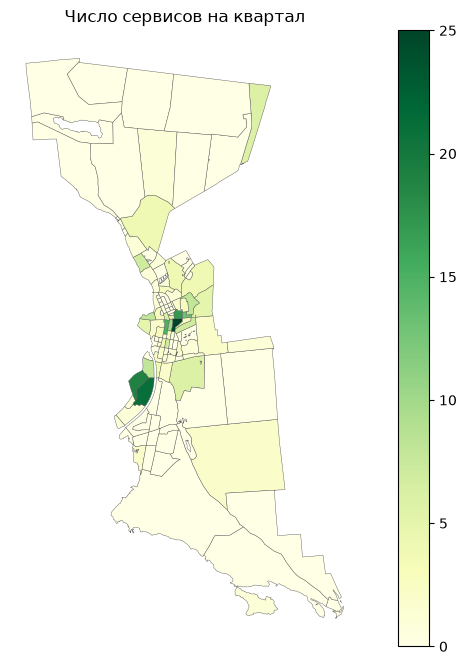

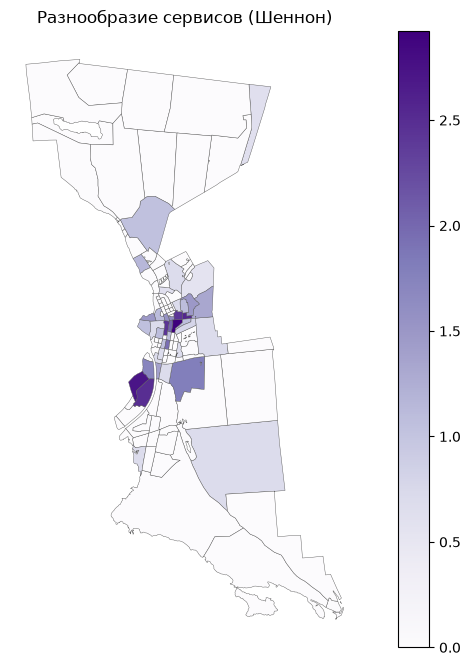

In [6]:
schools = gpd.read_file(PROCESSED_DIR / "schools.geojson")
kindergartens = gpd.read_file(PROCESSED_DIR / "kindergartens.geojson")
services_by_type = pd.read_csv(RESULTS_DIR / "services_by_type.csv")

display(pd.DataFrame({
    "Школы": [len(schools), schools["capacity"].sum()],
    "Детские сады": [len(kindergartens), kindergartens["capacity"].sum()],
}, index=["Объектов", "Суммарная вместимость, мест"]))
display(services_by_type)
show_layer(metrics, "Число сервисов на квартал", column="services_count", cmap="YlGn")
show_layer(metrics, "Разнообразие сервисов (Шеннон)", column="shannon_diversity", cmap="Purples")

## 5.1. ??????????? ???????? ?? ???????

??? ?????? ?????? ???????? ????????? ????? ?? ?????????? ??????? ?? ???? ?? ??????????? ?????
? ????? ???????? ? 15-???????? ????. ?????????? ? ???????????? ????? ???????? ?? ??? ????????? ????? ????????.


In [7]:
service_group_summary = pd.read_csv(RESULTS_DIR / "service_group_summary.csv")
service_access_wide = pd.read_csv(
    RESULTS_DIR / "service_group_accessibility_wide.csv", index_col="block_id"
)
display(service_group_summary)
display(
    service_access_wide[
        [
            column
            for column in [
                "service_access_social_min",
                "social_service_count_15min",
                "service_access_consumer_min",
                "consumer_service_count_15min",
            ]
            if column in service_access_wide.columns
        ]
    ].head(10)
)


,service_group,service_sphere,service_slug,objects_total,median_nearest_min,share_blocks_within_15,median_count_15
0,транспорт,consumer,transport,30,7.541636,0.651163,6.0
1,торговля,consumer,retail,34,9.179631,0.581395,2.0
2,услуги,consumer,household_services,14,10.644430,0.565891,2.0
3,туризм,consumer,tourism,6,13.293418,0.558140,1.0
4,общепит,consumer,food,7,15.905165,0.488372,0.0
5,инфраструктура,other,infrastructure,50,5.519975,0.713178,9.0
6,природа,other,nature,31,9.189341,0.759690,1.0
7,специальное,other,special,20,10.049022,0.581395,5.0
8,прочее,other,other,4,16.102248,0.449612,0.0
9,промышленность,other,industry,4,18.621019,0.356589,0.0


,service_access_social_min,social_service_count_15min,service_access_consumer_min,consumer_service_count_15min
block_id,,,,
0,6.212051,24,3.130883,52
1,0.000000,44,0.355910,76
2,21.730502,0,37.312441,0
3,4.214332,31,1.403754,44
4,0.000000,47,0.592592,73
5,2.552063,10,5.109201,12
6,0.084853,45,0.820775,72
7,2.961516,41,2.790972,69
8,0.000000,42,1.360495,64


## 6. Пешеходный граф и матрица доступности

Граф строится из `roads.geojson` со скоростью 5 км/ч. Для матрицы оставляется крупнейший
сильно связный компонент, после чего узлы перенумеровываются в непрерывный диапазон —
это требование IduEdu.

Узлов: 681
Рёбер: 1,666
Слабых компонент: 3


,Значение
Кварталов,129.000000
Пар всего,16641.000000
Достижимых пар,16641.000000
Недостижимых пар,0.000000
Доля недостижимых,0.000000
"Минимум, мин",0.000000
"Медиана, мин",40.594700
"Максимум, мин",241.189117
"Максимум на диагонали, мин",0.000000


Размер матрицы: (129, 129)


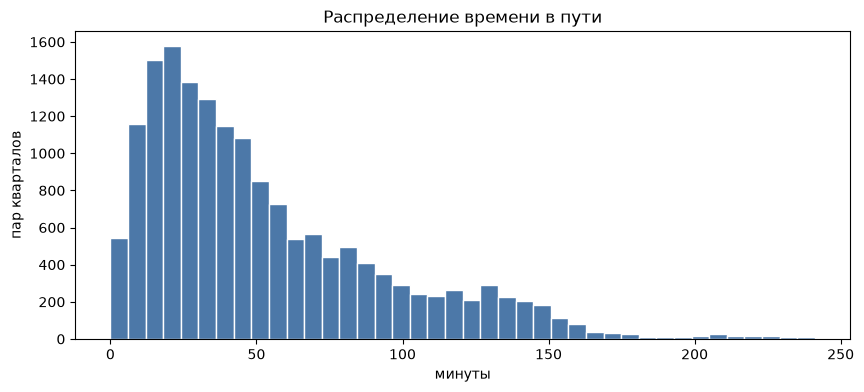

In [8]:
with open(PROCESSED_DIR / "graph_walk.pickle", "rb") as file:
    graph = pickle.load(file)

print(f"Узлов: {graph.number_of_nodes():,}")
print(f"Рёбер: {graph.number_of_edges():,}")
print(f"Слабых компонент: {nx.number_weakly_connected_components(graph)}")

accessibility_summary = pd.read_csv(RESULTS_DIR / "accessibility_summary_walk.csv")
display(accessibility_summary.T.rename(columns={0: "Значение"}))

matrix = pd.read_csv(RESULTS_DIR / "accessibility_matrix_walk_min.csv", index_col=0)
matrix.index.name = "from_block_id"
matrix.columns.name = "to_block_id"
print(f"Размер матрицы: {matrix.shape}")
finite = matrix.to_numpy()
finite = finite[np.isfinite(finite)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(finite, bins=40, color="#4c78a8", edgecolor="white")
ax.set_xlabel("минуты")
ax.set_ylabel("пар кварталов")
ax.set_title("Распределение времени в пути")
plt.show()

## 7. Обеспеченность школами и детскими садами

`competitive_provision` распределяет спрос между кварталами с учётом доступности:
15 минут для школ и 7 минут для детских садов. Нормативы — из конфигурации BlocksNet.

,block_id,capacity,demand,demand_within,provision_strong,provision_weak
0,0,0,0,0,NaN,NaN
1,1,0,7,7,1.0,1.0
2,2,0,0,0,NaN,NaN
3,3,0,12,0,0.0,0.0
4,4,0,125,125,1.0,1.0
5,5,0,0,0,NaN,NaN
6,6,0,2,2,1.0,1.0
7,7,0,23,23,1.0,1.0
8,8,0,6,0,0.0,0.0
9,9,0,41,0,0.0,0.0


,block_id
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


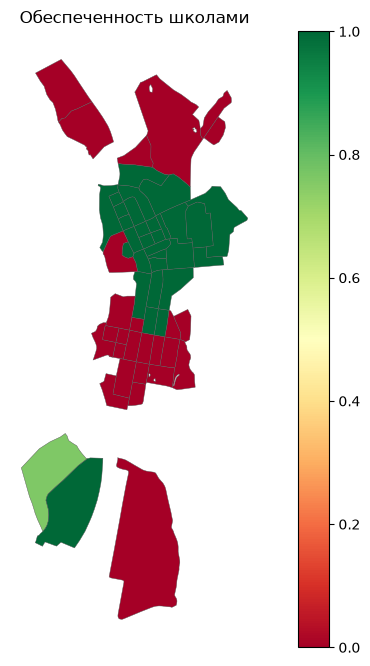

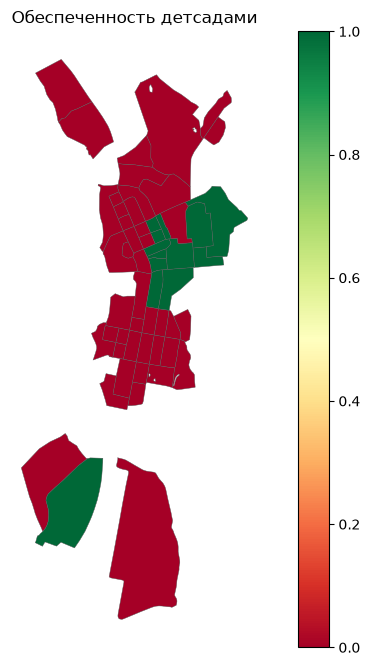

In [9]:
provision_school = pd.read_csv(RESULTS_DIR / "provision_school.csv")
provision_kindergarten = pd.read_csv(RESULTS_DIR / "provision_kindergarten.csv")

school_columns = ["block_id", "population", "capacity", "demand", "demand_within", "provision_strong", "provision_weak"]
kindergarten_columns = ["block_id", "population", "kindergarten_capacity", "kindergarten_demand", "kindergarten_demand_within", "kindergarten_provision_strong", "kindergarten_provision_weak"]

display(provision_school[[c for c in school_columns if c in provision_school.columns]].head(15))
display(provision_kindergarten[[c for c in kindergarten_columns if c in provision_kindergarten.columns]].head(15))
show_layer(metrics, "Обеспеченность школами", column="provision_strong", cmap="RdYlGn")
show_layer(metrics, "Обеспеченность детсадами", column="kindergarten_provision_strong", cmap="RdYlGn")

## 8. Морфотипы и итоговый слой

Spacematrix и Strelka — модельные категории BlocksNet. Итоговый слой `blocks_metrics.geojson`
содержит все показатели и используется дашбордом.

In [10]:
spacematrix_clusters = pd.read_csv(RESULTS_DIR / "spacematrix_clusters.csv")
display(spacematrix_clusters)
display(metrics["spacematrix_morphotype"].value_counts(dropna=False).rename_axis("Морфотип").to_frame("Кварталов"))
display(metrics["strelka_morphotype"].value_counts(dropna=False).rename_axis("Морфотип").to_frame("Кварталов"))

,cluster_id,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
0,0,1.000000,0.078702,0.800000,low-rise,low-density,residential,low-rise low-density residential
1,1,1.000000,0.132144,0.012476,low-rise,low-density,non-residential,low-rise low-density non-residential
2,2,3.818951,0.422698,0.734411,mid-rise,low-density,residential,mid-rise low-density residential
3,3,5.209607,0.931600,0.778532,mid-rise,low-density,residential,mid-rise low-density residential
4,4,1.000000,0.142415,0.523819,low-rise,low-density,mixed-use,low-rise low-density mixed-use
5,5,1.677240,0.287841,0.403098,low-rise,low-density,mixed-use,low-rise low-density mixed-use
6,6,2.940594,0.184130,0.709197,low-rise,low-density,residential,low-rise low-density residential
7,7,1.000000,0.015346,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
8,8,1.000000,0.220887,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
9,9,1.000000,0.063506,0.273499,low-rise,low-density,mixed-use,low-rise low-density mixed-use


,Кварталов
Морфотип,
None,55
low-rise low-density residential,26
low-rise low-density mixed-use,21
low-rise low-density non-residential,21
mid-rise low-density residential,6


,Кварталов
Морфотип,
None,55
low-rise model,32
low-rise non-residential,20
individual residential,19
mid-rise,3


## 9. Проверка результата

Проверки фиксируют размеры слоёв, CRS, диапазоны показателей, наличие исходной вместимости
и существование всех выходных файлов.

In [11]:
validation = pd.read_csv(RESULTS_DIR / "validation_summary.csv")
print(f"Проверок: {len(validation)}, провалено: {int((~validation['OK'].astype(bool)).sum())}")
display(validation)
display(metrics.drop(columns=["geometry", "block_id"], errors="ignore").head(10))

Проверок: 40, провалено: 0


,Проверка,OK,Подробности
0,Кварталы созданы,True,129 кварталов
1,Индексы кварталов уникальны,True,NaN
2,Матрица квадратная,True,"(129, 129)"
3,Нет отрицательных времён,True,минимум 0.000
4,Диагональ около нуля,True,максимум 0.000000
5,Население не отрицательное,True,"сумма 9,635 чел."
6,GSI не больше 1,True,максимум 0.351
7,Обеспеченность школами в диапазоне 0–1,True,от 0.000 до 1.000
8,Обеспеченность детсадами в диапазоне 0–1,True,от 0.000 до 1.000
9,Вместимость школ из исходных данных,True,NaN


,land_use,share,source_fid,residential,business,recreation,industrial,transport,special,agriculture,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,buildings_count,capacity,schools_count,capacity_is_estimate,kindergarten_capacity,kindergartens_count,kindergarten_capacity_is_estimate,site_area,fsi,gsi,mxi,l,osr,...,service_access_nature_min,service_access_other_min,service_access_recreation_min,service_access_retail_min,service_access_social_sphere_min,service_access_special_min,service_access_tourism_min,service_access_transport_min,culture_service_count_15min,education_service_count_15min,food_service_count_15min,healthcare_service_count_15min,household_services_service_count_15min,industry_service_count_15min,infrastructure_service_count_15min,nature_service_count_15min,other_service_count_15min,recreation_service_count_15min,retail_service_count_15min,social_sphere_service_count_15min,special_service_count_15min,tourism_service_count_15min,transport_service_count_15min,service_access_social_min,social_service_count_15min,service_access_consumer_min,consumer_service_count_15min,service_access_any_min,service_count_15min,osr_is_inf
0,recreation,0.712689,21,0.112491,0.007824,0.712689,0.000000,0.163356,0.003639,0.000000,0.0,0.0,0.000,0.000,0.000,0.000,0.0,0.0,0.0,0.0,False,0.0,0.0,False,1.710521e+05,0.000000,0.000000,NaN,NaN,NaN,...,0.000000,20.193406,8.527907,4.233353,14.757393,11.795955,14.985721,3.130883,6,5,5,7,8,0,11,4,0,5,27,1,7,1,11,6.212051,24,3.130883,52,0.000000,98,True
1,business,0.443157,3,0.269186,0.443157,0.083519,0.000000,0.204138,0.000000,0.000000,5.0,18.0,2560.101,4007.213,1793.158,1860.902,55.0,14.0,0.0,0.0,False,0.0,0.0,False,1.605700e+04,0.249562,0.159438,0.447483,1.565256,3.368150,...,10.322135,8.033178,2.776547,0.355910,13.697869,0.000000,2.825493,1.335638,13,6,7,10,12,2,28,3,1,14,32,1,15,4,21,0.000000,44,0.355910,76,0.000000,169,False
2,recreation,0.933478,67,0.000000,0.000000,0.933478,0.000000,0.000000,0.005030,0.061491,0.0,0.0,0.000,0.000,0.000,0.000,0.0,0.0,0.0,0.0,False,0.0,0.0,False,4.693297e+06,0.000000,0.000000,NaN,NaN,NaN,...,0.000000,41.253497,21.730502,43.394263,69.390234,39.771058,43.629567,37.312441,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,21.730502,0,37.312441,0,0.000000,2,True
3,residential,0.405240,0,0.405240,0.192583,0.180206,0.094764,0.127231,0.000000,0.000000,2.0,6.0,2364.278,5094.962,3384.653,1537.480,100.0,4.0,0.0,0.0,False,0.0,0.0,False,1.225039e+04,0.415902,0.192996,0.664314,2.154976,1.940370,...,6.079615,6.464833,4.214332,2.779799,26.076723,6.635248,1.403754,4.941037,13,2,3,6,9,0,21,1,1,10,17,0,10,4,11,4.214332,31,1.403754,44,1.403754,108,False
4,residential,0.675985,0,0.675985,0.000000,0.076930,0.033581,0.213504,0.000000,0.000000,7.0,39.0,8090.832,45812.087,35562.481,9977.809,1041.0,12.0,0.0,0.0,False,0.0,0.0,False,4.761553e+04,0.962125,0.169920,0.776269,5.662222,0.862757,...,9.971042,5.763979,3.361497,3.521450,18.046089,0.592592,4.378965,2.602984,17,6,7,9,12,1,27,2,1,15,31,0,14,4,19,0.000000,47,0.592592,73,0.000000,165,False
5,recreation,0.772491,0,0.004934,0.000000,0.772491,0.000000,0.064338,0.158237,0.000000,0.0,10.0,1907.462,1907.462,0.000,1525.971,0.0,10.0,0.0,0.0,False,0.0,0.0,False,1.242966e+05,0.015346,0.015346,0.000000,1.000000,64.163317,...,17.075645,12.868582,9.819085,13.967379,31.681476,12.240001,11.483569,5.109201,6,0,1,1,4,0,9,0,1,3,1,0,4,3,3,2.552063,10,5.109201,12,2.552063,36,False
6,business,0.727616,5,0.000000,0.727616,0.000000,0.000000,0.224970,0.047414,0.000000,2.0,20.0,5300.838,7648.214,307.603,5887.869,10.0,16.0,0.0,0.0,False,0.0,0.0,False,3.462497e+04,0.220887,0.153093,0.040219,1.442831,3.834116,...,9.497391,5.290328,0.084853,0.820775,15.587809,0.820775,3.109264,3.109264,16,6,7,9,12,1,26,3,1,14,31,0,14,4,18,0.084853,45,0.820775,72,0.084853,162,False
7,residential,0.691286,6,0.691286,0.045414,0.000000,0.000000,0.263300,0.000000,0.000000,3.0,17.0,3618.915,10678.816,6398.711,3744.021,188.0,8.0,0.0,0.0,False,0.0,0.0,False,2.

## 10. Сборка дашборда

Скрипт `report.py` читает сохранённые результаты и собирает `dashboard.html`.

In [12]:
subprocess.run([sys.executable, str(ROOT / "report.py")], check=True, cwd=ROOT)
IFrame("dashboard.html", width="100%", height=760)